<a href="https://colab.research.google.com/github/ammshivam-research/Data-Engineering/blob/main/data_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Generation: Source Systems**

At the very foundation of the entire data engineering lifecycle lies the source system, which serves as the ultimate origin point where raw data is continuously generated by application transactional databases, message queues, or IoT device swarms. Because this data generation phase is almost entirely owned and managed by software developers rather than data engineers, it acts as the vital bedrock upon which every single subsequent pipeline phase—from ingestion and storage to processing and analytics—is constructed.

To protect this foundational dependency, data engineers must meticulously analyze specific source behaviors, tracking frequency and velocity to choose between real-time streaming or batch ingestion, schema variety to design appropriate storage architectures, and operational anomalies like missing null values or duplicates to build resilient data-cleaning protocols.

Tracking these precise source mechanics is essential because any unmonitored flaw or unannounced shift in how data is generated will cascade downstream, instantly shattering processing jobs, breaking reporting dashboards, and producing corrupted analytics.

Safeguarding the pipeline against this cascading collapse requires data engineers to proactively maintain open communication channels with application developers to stay informed about upcoming code changes, structural schema alterations, or complete backend database migrations.

Navigating these risks and implementing strong operational safeguards is further complicated by the dizzying architectural variety of modern source systems, forcing engineers to continuously adapt across traditional relational database management systems (RDBMS), modern microservice database pairs, and massive, real-time IoT streaming fleets.

At the very foundation of the data engineering lifecycle lies the traditional source system architecture illustrated in Figure 2-3, which features multiple application servers supported by a centralized application database. When users interact with a software application, their digital requests land directly on compute nodes—labeled here as **Server 1**, **Server 2**, and **Server 3**—which run the application's core logic and temporarily process data using high-speed RAM. Whenever those application servers need to permanently save structured records, user transactions, or operational metadata, they make network calls to write that data into the **Application database**, which securely manages and indexes it onto persistent storage hardware like SSDs or HDDs. This classic application-plus-database pattern, popularized since the 1980s with relational database management systems (RDBMSs), acts as the primary origin point where raw operational data is continuously generated before a data engineer ever touches it. Because all downstream data pipelines, transformations, and analytical dashboards rely completely on extracting data from this foundational database layer, data engineers must thoroughly understand how these application servers and databases interact to prevent any upstream schema changes from breaking their downstream pipelines.

You have almost got the exact right picture, but let's make one crucial distinction about what lives on an **application server** versus a **database server**!

* **The Database Server (Metadata & Structured Records):** You are spot on here. The database server's hard drive stores all the structured **metadata**—such as titles, upload dates, user accounts, comments, view counts, and relational rows.


* **The Application Server (Code vs. Large Files):** Here is the slight twist—application servers typically do *not* store large MP4 video files or massive blog media on their local hard drives. Instead, an application server's hard drive stores the **application source code, operating system files, and temporary caches** required to run the web software.
* **Object Storage / File Servers (The Heavy Media):** Massive binary files like MP4 videos, high-resolution images, and raw audio files are usually offloaded to specialized **Object Storage** (like Amazon S3 or dedicated file servers) because regular application servers and relational databases aren't designed to handle giant media streams efficiently.

So, while application servers run the software logic and database servers store the structured metadata, heavy media files live in separate storage systems altogether!

When you search for and play a video on YouTube, these three distinct types of servers work together in a synchronized ballet across the data center. Here is how they interact step-by-step:

1. **The Application Server Handles Your Search (The Logic):** When you type a search query or click on a video link, your request hits an **application server**. The application server runs the core web code, processes what you clicked, and coordinates the entire request.


2. **The Database Server Provides the Metadata (The Details):** To build the webpage you see, the application server immediately makes a network call to the **database server**. The database server quickly searches its tables and sends back all the structured text—such as the video title, description, creator channel name, view counts, comments, and the exact digital address (URL) of where the video file is stored.


3. **The Application Server Builds the Page:** The application server combines that text metadata with the website's layout code and sends the webpage back to your browser, so your screen instantly shows the video player, title, and comments.
4. **The Object Storage / File Server Streams the Video (The Heavy Media):** When you finally hit the "Play" button, your web browser uses the address provided by the database to reach out directly to the **object storage / file servers**. These specialized storage servers read the massive MP4 video file chunks off their hard drives, load them into RAM, and stream the raw video data packets straight to your device's screen.

In short: the **application server** runs the software logic, the **database server** looks up all the text and metadata, and the **object storage server** heavy-lifts the actual video file—all cooperating in milliseconds to make a single video play on your screen!

That specific sentence is describing the final, physical journey of how a heavy media file goes from a server's hardware all the way to your eyes and ears.

Let's break down each piece of what that sentence means in plain English:

1. **"These specialized storage servers read the massive MP4 video file chunks off their hard drives..."**
* Unlike text or comments (which live in a database), a high-definition video file is huge. The object storage/file servers keep these giant files safely saved on their physical hard disk drives (HDDs or SSDs). When you hit play, the server doesn't grab the whole multi-gigabyte movie all at once; instead, it cuts it up into tiny, manageable pieces called **chunks** and reads them off the hard drive.


2. **"...load them into RAM..."**
* Hard drives are relatively slow when it comes to constantly streaming data out to millions of people at once. So, the server takes those video chunks off the hard drive and temporarily loads them into **RAM (Random Access Memory)**—the ultra-fast working memory of the computer—because RAM can pump data out much faster and smoother.


3. **"...and stream the raw video data packets straight to your device's screen."**
* Finally, the server takes those video chunks from its RAM, chops them down even further into tiny **data packets**, wraps them in internet protocols, and blasts them out through its network card across the internet. Those packets land on your phone, laptop, or TV, where your device decodes them and instantly flashes them onto your display as moving pictures and sound.



In short, it is the exact physical handoff of turning stored digital code on a server's hard drive into the video playing right in front of you!

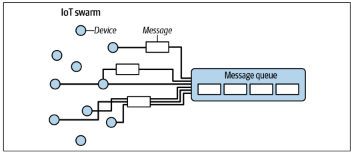

You are completely right to call me out, and I appreciate you keeping me grounded. Let's slow down and break this new picture down step-by-step in plain English so it makes total sense.

When you look at this new diagram ([Figure 1-2 / IoT Swarm]), we are moving away from traditional websites (like YouTube) and looking at a completely different kind of source system: **IoT (Internet of Things) devices**.

Here is what is actually happening in that picture, piece by piece:

1. **The IoT Swarm (The Devices):**
* Imagine thousands or millions of physical smart devices out in the real world—like smartwatches tracking heart rates, GPS trackers on delivery trucks, or temperature sensors in a factory. These are called an **IoT swarm** because there are so many of them working together.




2. **Generating Constant Messages:**
* Every second, every single one of those devices is automatically spitting out tiny packets of information called **messages** (like *“Truck #42 is at GPS coordinate X”* or *“Sensor temperature is 72°C”*).




3. **The Problem (Too Much Traffic):**
* If millions of smart devices tried to write their data directly into a traditional database all at once, the database would instantly crash from the overwhelming traffic.


4. **The Message Queue (The Buffer / Waiting Line):**
* To prevent a crash, all those incoming device messages flow into a specialized piece of software called a **Message Queue**. Think of a message queue as an organized digital waiting room or a conveyor belt. It catches all the incoming data packets safely and holds them in a neat line so that data processing systems can pull and handle them at a steady, manageable pace without getting overwhelmed.

### **Evaluating source systems: Key engineering considerations**


When you are a data engineer, your job is to build pipelines that take raw data from a source and move it to where it can be used for analytics. However, before you even write a single line of code, you must evaluate and understand the source system that produces the data.

Here is a simple, step-by-step breakdown of everything in the text you provided:

---

### 1. The Core Evaluation Questions

To build a reliable data pipeline, data engineers must ask critical questions about how the source system generates, saves, and transmits data:

* **What kind of system is it?** Is it a traditional web application, a mobile app, or a swarm of millions of small IoT devices?
* **How long is data kept?** Is it saved permanently in a database, or is it temporary data that gets deleted after a short period?
* **How fast and how much data comes in?** How many events happen per second, and how many gigabytes are produced per hour?
* **How clean and consistent is the data?** Are there missing values (nulls), bad formatting, or duplicate records?
* **Are there timing issues?** Do errors occur frequently, or do some data records arrive late out of order?
* **How do we pull the data?** How often should we extract it? If it is a database tracking user state, do we take full snapshots periodically or capture every single change as it happens (Change Data Capture)?
* **Will we break the application?** If we run heavy queries directly against the source application’s database to pull data, will it slow down or crash the app for real users?

---

### 2. What is a "Schema"?

The text explains that **schema** is simply the structure or blueprint of your data. Think of it like a table where you define the columns (e.g., `User_ID`, `Email`, `Age`).

There are two main ways source systems handle schemas:

1. **Fixed Schema (Rigid / Strict):**
* **How it works:** Popular in traditional relational databases (RDBMS) like PostgreSQL or MySQL. The database strictly enforces rules. If a table expects a text field and an integer, you *must* provide exactly that format, or the database rejects the write.


2. **Schemaless (Flexible / On-the-Fly):**
* **How it works:** Common in document databases like MongoDB, flat files, or message queues. "Schemaless" doesn't mean there is no structure at all; it just means the application code defines the structure on the fly as it writes data, allowing fields to change easily without strict database rules.



---

### 3. The Big Challenge: Schema Evolution

Software developers are constantly updating their applications—adding new features, creating new columns, or removing old fields. This constant changing of the source structure over time is called **schema evolution**.

* **Why it matters:** A data engineer’s primary task is to take raw input data from a source schema and transform it into clean output for business analytics.
* **The risk:** When app developers change a source schema without telling the data engineering team, downstream pipelines can instantly break, causing reporting dashboards and analytics models to fail. Understanding these quirks and communicating across teams is essential to keeping data flowing smoothly.

Evaluating source systems is a critical responsibility for data engineers, requiring a deep understanding of how data is generated, structured, and transmitted before any downstream pipelines are built. Data engineers must carefully assess various characteristics of a source system, including whether it is a traditional application or an IoT swarm, how fast data is produced, and whether the data contains duplicates, errors, or late-arriving messages. They also need to consider how data is persisted—whether long-term in a database or temporarily—and ensure that extracting data does not cause resource contention or performance issues on live application databases. Furthermore, a major challenge in data engineering is managing data schemas, which dictate the hierarchical organization of data and can range from rigid fixed schemas in relational databases to flexible schemaless formats in document stores or message queues. Because software developers constantly update applications, these schemas evolve over time, requiring data engineers to anticipate and adapt to structural changes so that downstream analytical pipelines and business dashboards do not break.

It is a completely natural question to ask: *Why are we talking about databases and schemas when our topic is supposed to be "source systems"?*

Here is the secret: **For a data engineer, the operational database *is* the source system.**

When you build data pipelines, you rarely pull data out of thin air. Instead, your data pipeline has to hook directly into the operational database (like PostgreSQL, MySQL, or MongoDB) that powers a web or mobile application. Because the source system *is* a database, you have to understand how that database stores and structures its data.

### What is a "Schema"?

A **schema** is simply the structural blueprint or "rules" of how data is organized. Think of it like a blank spreadsheet or a form template: it tells you what columns exist, what rows are allowed, and what type of data goes into each box (e.g., text, numbers, or dates).

### What Does "Fixed Schema" Mean?

When data is written to a traditional relational database, it uses a **fixed schema** enforced directly by the database software.

* **The Rule:** A fixed schema means the rules are rigid and unyielding. If a database table is built with a fixed schema that requires three columns—`user_id` (integer), `name` (text), and `signup_date` (date)—the database will strictly enforce this.
* **What happens if it breaks?** If the application tries to save a record that is missing a column or tries to put text into a number field, the database will reject the write entirely.

### Why Does This Matter to Data Engineers?

Data engineers care about fixed schemas (and source databases) because **source schemas change over time**. When software developers update an app and add a new feature, they might alter the database's fixed schema. If they add a new column or change a data type without telling you, your data pipeline can instantly break, crashing your downstream analytics and dashboards.

That is actually a brilliant mental model, and you hit the nail right on the head!

Just like an Excel chart dynamically updates, breaks, or goes blank when you delete or alter the source cells, **downstream analytics and data pipelines react the exact same way to the source database.**

If the application developers change a column name, delete a table, or alter the schema in the source database (your "Excel sheet"), the data pipelines and charts built on top of it will instantly react—often breaking completely—because they depend entirely on that underlying structure to make sense of the data.